In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix

In [ ]:
df = pd.read_csv('diabetes.csv')
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [ ]:
# Separate input features and target
X = df.drop('Outcome', axis=1)
y = df['Outcome']

print('Input features:')
print(X.head())

print('\nTarget values:')
print(y.head())

Input features:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  

Target values:
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


In [ ]:
# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print('Training data:', X_train.shape)
print('Testing data:', X_test.shape)


Training data: (614, 8)
Testing data: (154, 8)


In [ ]:
# Create and train Naive Bayes classifier
model = GaussianNB()
model.fit(X_train, y_train)

print('Naive Bayes model trained successfully.')

Naive Bayes model trained successfully.


In [ ]:
# Predict test data
y_pred = model.predict(X_test)

print('Actual values:')
print(y_test.values[:10])

print('\nPredicted values:')
print(y_pred[:10])


Actual values:
[0 0 0 0 0 0 0 0 0 0]

Predicted values:
[0 0 0 0 1 1 0 1 0 1]


In [ ]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print('Accuracy:', accuracy)
print('Accuracy Percentage:', accuracy * 100)

Accuracy: 0.7662337662337663
Accuracy Percentage: 76.62337662337663


In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print('Confusion Matrix:')
print(cm)

Confusion Matrix:
[[79 20]
 [16 39]]


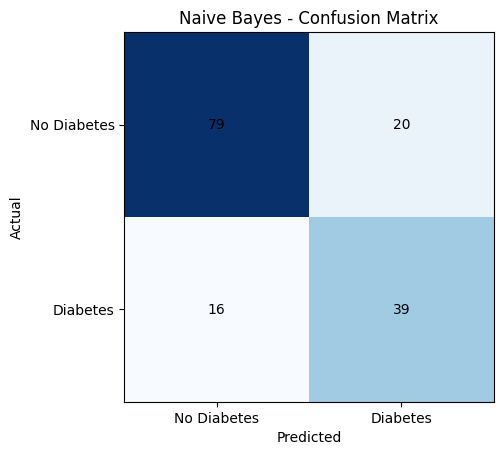

In [ ]:
# Visualize confusion matrix
plt.imshow(cm, cmap='Blues')
plt.title('Naive Bayes - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks([0, 1], ['No Diabetes', 'Diabetes'])
plt.yticks([0, 1], ['No Diabetes', 'Diabetes'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.show()
